# Kazakh Profanity Detection in Product Reviews
**KBTU · DSSC5113 · Bonus project** &nbsp;|&nbsp; **Author:** `<Nurbolat Nuray, 25MD0171>` &nbsp;|&nbsp;.

**Task.** Input: one Kazakh review or comment. Output: label `0` (no Kazakh profanity) or `1` (profanity present) together with a probability.

**Approach.** Reviews are short and noisy: Latin transliteration, masked words (`қо***бас`), typos, mixed Kazakh/Russian. So the model is a **TF-IDF (character + word n-grams) → logistic regression** classifier, trained on CPU in seconds, preceded by a hand-written *stateless* normalisation step. Training settings and the decision threshold are chosen on the validation set; the test set is used exactly once.

| § | Section | § | Section |
|---|---|---|---|
| 1 | Setup | 6 | Test evaluation |
| 2 | Data and labeling rules | 7 | Error analysis and stress set |
| 3 | Text normalisation | 8 | One comment, step by step |
| 4 | Cleaning and train/val/test split | 9 | Predict on text |
| 5 | Model and training | 10 | Limitations |



## 1. Setup

In [ ]:
import json, re, unicodedata, itertools, platform, warnings
from functools import partial
import numpy as np, pandas as pd, joblib, sklearn
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer, HashingVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import precision_recall_fscore_support as prf, confusion_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 100)

SEED = 42
RAW_XLSX, CLEAN_CSV = "data/raw/kazakh_profanity_share.xlsx", "data/processed/kazakh_profanity_clean.csv"
MODEL_PATH, META_PATH = "models/model.joblib", "models/model_meta.json"
NEAR_DUP_COSINE = 0.8                      # char-3..5-gram cosine above this => near-duplicate
GRID = dict(C=[1, 3, 10, 30], char_ngram_max=[4, 5], family_alpha=[0.0, 0.5], max_words=[50, 150])

import os
for d in ["data/processed", "models", "results"]: os.makedirs(d, exist_ok=True)
np.random.seed(SEED)
print(f"seed={SEED} | python {platform.python_version()} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")

seed=42 | python 3.12.3 | scikit-learn 1.9.1 | pandas 3.0.6


## 2. Data and labeling rules

**Source.** `data/raw/kazakh_profanity_share.xlsx` — 3,061 comments with columns `kazsandra_id, text, label, split`. The ids follow the KazSAndRA naming scheme: these are user reviews/comments about Kazakh apps and services (Kaspi, games, etc.), i.e. product/service reviews. **There are no synthetic examples in train/val/test**; the only synthetic data is the 19-sentence stress set in §7 (qualitative check only).

**Labeling rules** (the existing labels were checked against *this* task, not against toxicity or sentiment):

| Case | Rule |
|---|---|
| Obscene/insulting word (қотақ, зайбал, ам, шешеңнің амы, нахуй, сука, пиздец, ешак…) | `1` |
| Masked (`қо***бас`, `н*ху`), misspelled (`заибал`, `котаккк`), or written in Latin (`qotaq`) | `1` — same word, different spelling |
| Mixed Kazakh/Russian/English comment | label by the *presence* of a profane word, whatever the language of the rest |
| Negative or angry review **without** a profane word | `0` — a bad review is not profanity |
| Ambiguous word **«мал»**: livestock (*мал шаруашылығы, қара мал*) vs. insult ("beast") | livestock `0`, insult `1` |
| Borderline slang («шайтан кошмар») | follow the dataset label; discussed in §7 |

**Known skew.** The dataset author warned that «мал» appears almost only in profane texts, so a naive model would learn *«мал» ⇒ profane*. §3–§5 contain my countermeasures; no augmentation is used because it was reported to raise false positives.

In [ ]:
raw = pd.read_excel(RAW_XLSX)
print("rows:", len(raw), "| columns:", list(raw.columns))
print(raw.label.value_counts().rename({1: "profane (1)", 0: "clean (0)"}).to_string())
has_mal = raw.text.str.lower().str.contains(r"\bмал")
print("\ntexts containing a word that starts with 'мал', by label:")
print(pd.crosstab(raw.label, has_mal, rownames=["label"], colnames=["has 'мал*'"]).to_string())
raw.sample(6, random_state=SEED)[["text", "label"]]      # labeled examples

rows: 3061 | columns: ['kazsandra_id', 'text', 'label', 'split']
label
profane (1)    1538
clean (0)      1523

texts containing a word that starts with 'мал', by label:
has 'мал*'  False  True 
label                   
0            1472     51
1            1142    396


,text,label
1765,Щещенсгин жазлп жатканда шкп каита крсем каита установить деп турго разбортчик истешиш шешенсгин...,1
203,Өте күшті ойын 😍😍😍😍😍,0
1356,"Мал, ишак қотақбас жаман ойын 👎🤬🤬",1
1451,Қотақтың басы да қызық емес,1
1577,Бұл приложения өте керемет бірақ академия амбрелло деген сериялга жасасаныздар керемет болатын е...,0
102,Қотақ жеген қотақтың кірі. Мета мен ұжымына сігіліп кетуін тілеймін.,1


## 3. Text normalisation

`normalize()` maps every spelling variant to one canonical form. It is **stateless** (nothing is learned from data), so it cannot leak test information. Steps: lowercase → remove URLs → `@` used as a letter (`қот@қ`) → *per token*: Latin→Cyrillic transliteration (`qotaq→котак`), Kazakh letters folded to Russian (`қ→к, ы→и, ү→у`), masks restored when the pattern matches a known profane lemma (`қо***бас→котакбас`), repeated letters collapsed, digits→`0` → livestock phrases replaced by the neutral token `livestock`. Punctuation and emojis are dropped; only the first `max_words` words of a long comment are kept.

The small word lists below are **not** an inference-time classifier. They only serve (1) to group profane training examples into *families* so that very frequent words (like «мал») can be down-weighted, and for per-family recall; (2) to neutralise livestock contexts; (3) to restore masked words.

In [ ]:
FAMILIES = [
 ("kotak",  r"кота?к|котен|котин"),      ("zaibal", r"заиба|заеба|заеб|заибл"),
 ("pizd",   r"пизд|пзд"),                ("blya",   r"\bбля|блят|\bблд"),
 ("nahui",  r"\bнаху|нахуи|\bнахер|\bнах\b"),  ("suka", r"\bсука|\bсуки|\bсучк|\bсук\b"),
 ("sheshe", r"шеше[нс]|шешин|\bанан"),   ("am",     r"\bам\b|\bами\b|\bамин|\bамка|\bамси|\bамн\b"),
 ("sik",    r"\bсик|\bсиг|\bсгн"),       ("eshak",  r"\bеша[кг]|\bешек|\bесек|\bиша[кг]|\bишек|\bит\b"),
 ("govno",  r"говн|гавн|\bбокт|\bбокка"), ("chort",  r"чорт|\bшшс|далба[ие]?о?п?|далбае"),
 ("ebat",   r"\bебан|\bебат|\bебал|\bеби\b|\bебла|еблан"),
 ("huy",    r"\bхуи|\bхуе|\bхуя|хули|\bхер\b|херн"),
 ("mudak",  r"мудак|гандон|\bлох\b|дебил|\bурод|идиот"),
 ("mal",    r"\bмал"),                   # ambiguous "cattle"/insult - weakest family, checked last
]
_FAM = [(n, re.compile(p)) for n, p in FAMILIES]
def family_of(norm_text):
    for n, p in _FAM:
        if p.search(norm_text): return n
    return "other"

BENIGN = re.compile(r"\bмал\s+шаруаш\w*|\b(?:ири\s+)?кара\s+мал\w*|\bусак\s+мал\w*|\bторт\s+тулик\s+мал\w*"
                    r"|\bмал[-\s]?кора\w*|\bмал\s+сат\w*|\bмал\s+баг\w*")
MASK_LEMMAS = ["котак","котакбас","котакбастар","заибал","заебал","пиздец","пиздес","бля","блят","наху","нахуи",
  "сука","суки","сикти","сикир","гандон","хуи","хуиня","ебан","ебат","ебал","далбаеб","мудак","шешен","шешенин",
  "ешак","говно","чорт","херня"]

# ---------- normalisation ----------
FOLD = str.maketrans({"ә":"а","ə":"а","ғ":"г","қ":"к","ң":"н","ө":"о","ү":"у","ұ":"у","һ":"х",
                      "і":"и","ы":"и","й":"и","э":"е","ё":"е","ъ":"","ь":""})
_PRE = {"ý":"у","ə":"а","ı":"и","ö":"о","ü":"у","ū":"у"}
_DIG = [("sh","ш"),("ch","ч"),("zh","ж"),("ya","я"),("yu","ю")]
_LAT = dict(zip("abcdefghijklmnopqrstuvwxyz", "абсдефгхижклмнопкрстуввхиз"))
_CYR = re.compile(r"[а-яәғқңөұүһіё]")
_URL = re.compile(r"https?://\S+|www\.\S+|\S+@\S+\.\S+")

def _translit(t):
    for k, v in _PRE.items(): t = t.replace(k, v)
    t = "".join(c for c in unicodedata.normalize("NFKD", t) if not unicodedata.combining(c))
    for a, b in _DIG: t = t.replace(a, b)
    return "".join(_LAT.get(c, c) for c in t)

def _unmask(tok):
    """'қо***бас' -> 'котакбас' if the mask pattern fits a known lemma, else just drop the mask symbols."""
    if not re.search(r"[^*#]", tok): return ""
    if len(tok) < 3: return tok.replace("*", "").replace("#", "")
    parts, runs = re.split(r"[*#]+", tok), re.findall(r"[*#]+", tok)
    pat = "".join(re.escape(p) + (".{1,%d}" % (len(runs[i]) + 1) if i < len(runs) else "") for i, p in enumerate(parts))
    for lem in MASK_LEMMAS:
        if re.fullmatch(pat, lem): return lem
    return tok.replace("*", "").replace("#", "")

def normalize(text, max_words=150):
    t = unicodedata.normalize("NFC", str(text)).lower()
    t = _URL.sub(" ", t)
    t = re.sub(r"(?<=[\w*])@|@(?=[\w*])", "а", t)                # қот@қ -> қотақ
    out = []
    for tok in re.findall(r"[\w*#]+", t)[:max_words]:            # long comments: first max_words words only
        if not _CYR.search(tok): tok = _translit(tok)
        tok = tok.translate(FOLD)
        if "*" in tok or "#" in tok: tok = _unmask(tok)
        tok = re.sub(r"(.)\1+", r"\1", tok)                       # 'котаккк' -> 'котак'
        tok = re.sub(r"\d+", "0", tok)
        if tok: out.append(tok)
    return BENIGN.sub(" livestock ", " ".join(out)).strip()

demo = ["Қо***бас қосымша!!!", "qotaqbas ойын", "Бұл ойын зайбалллл 😡", "Біз қара мал сатып алдық", "Өте жақсы қосымша, рахмет"]
pd.DataFrame({"raw": demo, "normalized": [normalize(t) for t in demo]})

,raw,normalized
0,Қо***бас қосымша!!!,котакбас косимша
1,qotaqbas ойын,котакбас оин
2,Бұл ойын зайбалллл 😡,бул оин заибал
3,Біз қара мал сатып алдық,биз скотоводство сатип алдик
4,"Өте жақсы қосымша, рахмет",оте жакси косимша рахмет


## 4. Cleaning and train / val / test split

Each step keeps the evaluation honest:
1. **Label fixes** — only unambiguous errors found by an out-of-fold audit (a model trained without the example strongly disagreed with its label): 2 rows.
2. **Personal data** — emails, links, phone numbers and @handles are removed; reviewer ids are **not** written to the output CSV.
3. **Duplicates** — exact duplicates *after normalisation* are dropped (conflicting labels would be dropped too; there were none).
4. **Near-duplicates** — texts with char 3–5-gram cosine > 0.8 are merged into groups. A `HashingVectorizer` is used (no fitted vocabulary), so nothing is learned from the data here.
5. **Group split** with `StratifiedGroupKFold(10, seed=42)`: 1 fold test, 1 fold val, 8 folds train. A group never crosses splits. The original `split` column is discarded because near-duplicates sat in different splits there (leakage).

In [ ]:
df = raw.drop(columns=["split"]).copy()
info = {"raw_rows": len(df)}

# 1) label fixes (found by an out-of-fold audit; both are unambiguous insults that were labeled 0)
LABEL_FIXES = {"pla012126pla": 1,   # "Қотақбас екен"      - unambiguous insult
               "pla077406pla": 1}   # "Қотақ амсын ..."    - explicit profanity
for _id, lab in LABEL_FIXES.items(): df.loc[df.kazsandra_id == _id, "label"] = lab
info["label_fixes"] = len(LABEL_FIXES)

# 2) personal data: emails, links, phone numbers, @handles
PII = re.compile(r"https?://\S+|www\.\S+|\S+@\S+\.\S+|\+?\d[\d\s\-()]{8,}\d|(?<!\w)@\w+")
info["rows_with_pii_scrubbed"] = int(df.text.str.contains(PII).sum())
df["text"] = df.text.astype(str).str.replace(PII, " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

# 3) duplicates by normalised text
df["key"] = df.text.map(lambda t: normalize(t, 10**6))
df = df[df.key != ""]
g = df.groupby("key").label.nunique(); conflict = g[g > 1].index
info["dropped_conflicting_duplicates"] = int(df.key.isin(conflict).sum())
df = df[~df.key.isin(conflict)]
n = len(df); df = df.drop_duplicates("key").reset_index(drop=True)
info["dropped_exact_duplicates"] = n - len(df)

# 4) near-duplicates -> connected components = groups
X = HashingVectorizer(analyzer="char_wb", ngram_range=(3, 5), n_features=2**18, alternate_sign=False).transform(df.key)
S = (X @ X.T).tocsr(); S.data = (S.data > NEAR_DUP_COSINE).astype(np.int8); S.eliminate_zeros()
n_groups, df["group"] = connected_components(S, directed=False)
info["n_near_dup_groups"] = int(n_groups)

# 5) group-aware stratified split
fold = np.zeros(len(df), int)
for k, (_, idx) in enumerate(StratifiedGroupKFold(10, shuffle=True, random_state=SEED).split(df, df.label, df.group)):
    fold[idx] = k
df["split"] = np.where(fold == 0, "test", np.where(fold == 1, "val", "train"))
df[["text", "label", "split", "group"]].to_csv(CLEAN_CSV, index=False)      # no reviewer ids

tr, va, te = [df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"]]
assert not set(tr.group) & set(te.group) and not set(tr.group) & set(va.group), "near-duplicates leak across splits"
info.update(final_rows=len(df), seed=SEED, **{s: dict(n=len(d), label0=int((d.label == 0).sum()), label1=int((d.label == 1).sum()))
                                              for s, d in zip(["train", "val", "test"], [tr, va, te])})
json.dump(info, open("data/split_info.json", "w"), indent=2)
print({k: v for k, v in info.items() if k not in ("train", "val", "test")})
pd.DataFrame({s: [len(d), (d.label == 0).sum(), (d.label == 1).sum()] for s, d in zip(["train", "val", "test"], [tr, va, te])},
             index=["n", "clean (0)", "profane (1)"]).T

{'raw_rows': 3061, 'label_fixes': 2, 'rows_with_pii_scrubbed': 15, 'dropped_conflicting_duplicates': 0, 'dropped_exact_duplicates': 33, 'n_near_dup_groups': 2854, 'final_rows': 3027, 'seed': 42}


,n,clean (0),profane (1)
train,2423,1215,1208
val,302,151,151
test,302,151,151


## 5. Model and training

**Model.** `TfidfVectorizer(char_wb 2..k)` ∪ `TfidfVectorizer(word 1–2-grams)` → `LogisticRegression(liblinear, L2)`.
*Why:* only ~2.4k training examples; spelling is noisy, and character n-grams are robust to that; trains in seconds on CPU; the decision can be explained feature by feature (§8). A fine-tuned multilingual transformer would be the natural next step; I did not use one.

**Text → model input.** `normalize()` (§3) → two sparse TF-IDF vectors. The vocabulary is fitted on **train only**. Unknown words are not lost: they are still covered by character n-grams. Long comments: only the first `max_words` words are used. Punctuation and emojis are dropped by the normaliser.

**Family weights.** A profane training example of family *f* gets weight `(mean family size / n_f) ** alpha`, so frequent words (like «мал») count less. `alpha=0` is plain training; the total positive weight is kept constant.

**Choosing settings.** Grid search over `C`, n-gram length, `alpha`, `max_words` and the decision threshold; criterion = F1 of the profanity class **on validation**. The test set is not touched here.

In [ ]:
def build_pipeline(C=10.0, char_ngram_max=5, max_words=150, seed=SEED):
    prep = partial(normalize, max_words=max_words)
    feats = FeatureUnion([
        ("char", TfidfVectorizer(preprocessor=prep, analyzer="char_wb", ngram_range=(2, char_ngram_max),
                                 sublinear_tf=True, min_df=2, lowercase=False)),
        ("word", TfidfVectorizer(preprocessor=prep, ngram_range=(1, 2), sublinear_tf=True, min_df=1,
                                 lowercase=False, token_pattern=r"\S+"))])
    return Pipeline([("features", feats),
                     ("clf", LogisticRegression(C=C, solver="liblinear", max_iter=2000, random_state=seed))])

def family_weights(norm_texts, labels, alpha=0.5):
    labels = np.asarray(labels)
    fam = np.array([family_of(t) if l == 1 else "neg" for t, l in zip(norm_texts, labels)])
    names, cnt = np.unique(fam[labels == 1], return_counts=True)
    size, mean = dict(zip(names, cnt)), cnt.mean()
    w = np.array([(mean / size[f]) ** alpha if f != "neg" else 1.0 for f in fam])
    w[labels == 1] *= (labels == 1).sum() / w[labels == 1].sum()      # keep total positive mass unchanged
    return w

def fit(C, ng, alpha, mw):                                            # TRAIN rows only
    p = build_pipeline(C, ng, mw)
    w = family_weights([normalize(t, mw) for t in tr.text], tr.label, alpha)
    return p.fit(tr.text, tr.label, clf__sample_weight=w)

def best_thr(y, p):                                                   # threshold maximising F1 (on val)
    ts = np.arange(0.05, 0.96, 0.01)
    f = [prf(y, p >= t, average="binary", zero_division=0)[2] for t in ts]
    return float(ts[int(np.argmax(f))]), float(max(f))

rows = []
for C, ng, a, mw in itertools.product(*GRID.values()):
    pv = fit(C, ng, a, mw).predict_proba(va.text)[:, 1]
    t, f = best_thr(va.label, pv)
    rows.append(dict(C=C, char_ngram_max=ng, family_alpha=a, max_words=mw, thr=round(t, 2), val_f1=round(f, 4)))
grid = pd.DataFrame(rows).sort_values("val_f1", ascending=False).reset_index(drop=True)
grid.to_csv("results/val_grid.csv", index=False)
print(f"{len(grid)} combinations evaluated on validation; top 6 by val F1:")
grid.head(6)

32 combinations evaluated on validation; top 6 by val F1:


,C,char_ngram_max,family_alpha,max_words,thr,val_f1
0,30,4,0.5,50,0.42,0.9316
1,30,5,0.5,50,0.40,0.9316
2,10,5,0.5,50,0.40,0.9316
3,10,4,0.0,50,0.45,0.9307
4,30,5,0.5,150,0.40,0.9281
5,10,5,0.5,150,0.41,0.9281


In [ ]:
b = grid.iloc[0]
best = dict(C=float(b.C), char_ngram_max=int(b.char_ngram_max), family_alpha=float(b.family_alpha), max_words=int(b.max_words))
thr = float(b.thr)
model = fit(best["C"], best["char_ngram_max"], best["family_alpha"], best["max_words"])
joblib.dump(model, MODEL_PATH)                                        # preprocessing + vocabulary + weights in one file
json.dump(dict(best_params=best, threshold=thr, seed=SEED, sklearn=sklearn.__version__, python=platform.python_version()),
          open(META_PATH, "w"), indent=2)
print("selected on validation:", best, "| threshold:", thr, "| val F1:", b.val_f1)

selected on validation: {'C': 30.0, 'char_ngram_max': 4, 'family_alpha': 0.5, 'max_words': 50} | threshold: 0.42 | val F1: 0.9316


## 6. Test evaluation (once)

The test set was not used for training, for choosing parameters, or for choosing the threshold.

- **False positive (FP):** a clean review flagged as profane — an honest user is blocked or penalised, moderators get extra work.
- **False negative (FN):** profanity slips through and the insult is published.
- If flagged reviews go to a human moderator, **misses (FN) are usually costlier**, and the threshold can be lowered to gain recall. If hiding is automatic, false positives are costlier.

n_test = 302 | threshold = 0.42
profanity class:  precision = 0.952   recall = 0.921   F1 = 0.936
TN=144  FP=7  FN=12  TP=139

recall by profanity family (unreliable for small n):


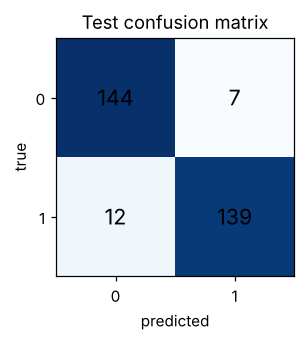

family,kotak,mal,zaibal,other,eshak,chort,blya,nahui,sheshe,pizd,am,govno,sik,huy
n,38.000,23.000,17.000,16.000,9.0,9.000,8.0,7.0,6.000,6.000,4.0,3.000,3.0,2.0
recall,0.947,0.957,0.941,0.875,1.0,0.889,1.0,1.0,0.833,0.667,1.0,0.667,1.0,0.5


In [ ]:
te = te.copy()
te["prob"] = model.predict_proba(te.text)[:, 1]
te["pred"] = (te.prob >= thr).astype(int)
p, r, f, _ = prf(te.label, te.pred, average="binary", zero_division=0)
cm = confusion_matrix(te.label, te.pred, labels=[0, 1])
print(f"n_test = {len(te)} | threshold = {thr}")
print(f"profanity class:  precision = {p:.3f}   recall = {r:.3f}   F1 = {f:.3f}")
print(f"TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")

fig, ax = plt.subplots(figsize=(3.6, 3.2)); ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Test confusion matrix"); fig.tight_layout(); fig.savefig("results/confusion_matrix.png", dpi=150); plt.show()

te["family"] = [family_of(normalize(t, best["max_words"])) for t in te.text]
te.drop(columns=["group", "split"]).to_csv("results/test_predictions.csv", index=False)
fam = te[te.label == 1].groupby("family").pred.agg(n="size", recall="mean").sort_values("n", ascending=False).round(3)
print("\nrecall by profanity family (unreliable for small n):")
fam.T

**Reading the result.** Precision 0.95 / recall 0.92 / F1 0.94 on a balanced test set of 302 comments: of 151 profane comments 139 are found, and only 7 of 151 clean ones are flagged. With n = 302 the 95 % interval is roughly ±3 points, so differences of 1–2 points are not meaningful. Rare words (`huy`, `pizd`, `govno`) have very low support, so their recall values are anecdotal.

## 7. Error analysis and stress set
All wrong test predictions, sorted by predicted probability:

In [ ]:
err = te[te.label != te.pred].sort_values("prob")
err = err.assign(kind=np.where(err.label == 1, "FN (missed)", "FP (false alarm)"), text=err.text.str[:105])
te[te.label != te.pred].sort_values("prob").drop(columns=["group", "split"]).to_csv("results/test_errors.csv", index=False)
err[["text", "prob", "family", "kind"]].round(2).reset_index(drop=True)

,text,prob,family,kind
0,2.11.2021. Күзетшілер Мас! Шлагбаумды ашып жаба алмайды. Телефондарына қоңырау шалсақ мас күзетш...,0.08,govno,FN (missed)
1,Бұл ойын жақсы ойын. Менің інім осыны көшір көшір дейді. Ең басында менсінбеп едім. Артынан менд...,0.09,chort,FN (missed)
2,",саган унамады ой Кент олардн котендери улкен",0.09,kotak,FN (missed)
3,Каспий мал бөліп төлеуге болады дар алып бөліп төлеуге растау бермейді ғой мал Каспий мал бөліп ...,0.10,mal,FN (missed)
4,В п*зду бұндай приложение банктарыңның бір жерін с*гейін..жылына бір рет распродажа ұйымдастырам...,0.16,pizd,FN (missed)
5,Но мына ойын хуйз нят уайфаймен ойналады мен бірінші нұсқасын екіншісін үшіншісін де уайфаймен о...,0.16,huy,FN (missed)
6,Күшті бірақ қата берет😡 б#ә,0.17,other,FN (missed)
7,Керемет жасалған дүние. Өте ыңғайлы Теріс пікір қалдырған көттерінді қысындар,0.21,other,FN (missed)
8,Мәссаған не деген керемет оиын пздц жостка 👍🏻👍🏻😍,0.26,pizd,FN (missed)
9,Өте өте дәу екен ғой біреудің меншігіндегі және оған теңестірілген соттардың төрағалары мен сот ...,0.30,kotak,FN (missed)


**Mistakes and likely causes** (at least three required; here five):

1. **FN: «В п\*зду бұндай приложение… с\*гейін»** (p ≈ 0.16). Heavy masking and abbreviations (`п*зду`, `пздц`) are not covered by my mask-lemma list. *Fix:* character-level mask-aware matching or a longer lemma list, plus more masked training examples.
2. **FN: «Каспий мал бөліп төлеуге болады… тағы түк ұнамады»** (p ≈ 0.10) and **«Күзетшілер Мас!… Боқтық сөйлеп…»** (p ≈ 0.08). There is no explicit profane word in the first and only the mild «боқтық» in the second, so this is most likely **label noise** (labelled 1 because of «мал» or general toxicity). *Fix:* re-annotation by two people, starting with the out-of-fold rows with the strongest disagreement.
3. **FP: «Кашан атын кайта коясындар?»** (0.61), **«КІМ БОТАҚҚА БАРМАЙДЫ…»** (0.54), **«Шайтан кошмар»** (0.44). Angry colloquial tone and slang-looking words sit near the threshold; even human annotators may disagree. *Fix:* a guideline for borderline words, and a higher threshold if precision matters more.
4. **FN: a long comment with one profane word** («реклама заебал…», p ≈ 0.36). The signal is diluted by the clean text. *Fix:* split long comments into sentences and take the maximum sentence score.
5. **The word «мал».** Because of the data skew the model still partly links it to profanity (stress set below). The real fix is more clean examples with «мал» (livestock, market, farming).

### Stress set — 19 hand-written sentences (**synthetic**, qualitative check only, not part of train/val/test)

In [ ]:
STRESS = [  # (text, label): livestock «мал» = 0, insult = 1, plain negative reviews = 0, masked/Latin/mixed profanity = 1
 ("Мал шаруашылығы туралы қызық мақала", 0), ("Біз қара мал сатып алдық", 0),
 ("Қой мен ешкі ұсақ мал және сиыр ірі қара мал", 0), ("Малды базарға апарды", 0), ("Mal sharuashylyǵy damyp jatyr", 0),
 ("Өте жақсы қосымша рахмет", 0), ("Өте нашар қосымша жұмыс істемейді", 0),
 ("Тапсырыс келмеді ақшамды қайтарыңдар", 0), ("Ойын ұнамады баяу жұмыс істейді", 0),
 ("Қотақбас ойын жүктемеңдер", 1), ("Qotaqbas qosymsha", 1), ("Қо***бас қосымша", 1), ("Мына ойынды шығарған мал", 1),
 ("Бұл ойын зайбал екен", 1), ("Zaibal oiyn pizdec", 1), ("Н*ху керек бұл қосымша", 1), ("Шешеңнің амы ойын", 1),
 ("Рахмет керемет қосымша бірақ жеткізушілер малдар", 1), ("Ойын говно сука қате береді", 1)]
st = pd.DataFrame(STRESS, columns=["text", "label"])
st["prob"] = model.predict_proba(st.text)[:, 1]; st["pred"] = (st.prob >= thr).astype(int)
st["ok"] = np.where(st.pred == st.label, "", "WRONG")
st.to_csv("results/stress_predictions.csv", index=False)

neg_mal = te[(te.label == 0) & te.text.str.lower().str.contains(r"\bмал|\bmal")]
res = dict(n_test=int(len(te)), precision=round(p, 4), recall=round(r, 4), f1=round(f, 4), threshold=thr,
           confusion_matrix=dict(TN=int(cm[0,0]), FP=int(cm[0,1]), FN=int(cm[1,0]), TP=int(cm[1,1])),
           recall_by_family=fam.recall.to_dict(),
           stress_set=dict(n=len(st), accuracy=round(float((st.pred == st.label).mean()), 3)),
           clean_test_texts_with_mal=dict(n=int(len(neg_mal)), false_positives=int(neg_mal.pred.sum())))
json.dump(res, open("results/test_metrics.json", "w"), indent=2, ensure_ascii=False)
print(f"stress accuracy: {res['stress_set']['accuracy']} ({(st.pred == st.label).sum()}/{len(st)}) | "
      f"clean test texts with 'мал': {len(neg_mal)}, false positives: {int(neg_mal.pred.sum())} (too few to prove anything)")
st.round(2)

stress accuracy: 0.842 (16/19) | clean test texts with 'мал': 3, false positives: 0 (too few to prove anything)


,text,label,prob,pred,ok
0,Мал шаруашылығы туралы қызық мақала,0,0.30,0,
1,Біз қара мал сатып алдық,0,0.17,0,
2,Қой мен ешкі ұсақ мал және сиыр ірі қара мал,0,0.79,1,WRONG
3,Малды базарға апарды,0,0.51,1,WRONG
4,Mal sharuashylyǵy damyp jatyr,0,0.39,0,
5,Өте жақсы қосымша рахмет,0,0.00,0,
6,Өте нашар қосымша жұмыс істемейді,0,0.00,0,
7,Тапсырыс келмеді ақшамды қайтарыңдар,0,0.34,0,
8,Ойын ұнамады баяу жұмыс істейді,0,0.01,0,
9,Қотақбас ойын жүктемеңдер,1,0.99,1,


## 8. One comment, step by step

raw text → `normalize()` → two TF-IDF vectorizers → logit = Σ(feature value × weight) + intercept → sigmoid → probability → compare with the threshold.

In [ ]:
text = "Қо***бас қосымша, нахуй керек"
print("0 raw        :", text)
print("1 normalize  :", normalize(text, best["max_words"]))

feats, clf = model.named_steps["features"], model.named_steps["clf"]
vec = feats.transform([text]); names = feats.get_feature_names_out()
nz = vec.nonzero()[1]; contrib = {names[j]: vec[0, j] * clf.coef_[0][j] for j in nz}
print(f"2 TF-IDF     : {len(nz)} non-zero features; strongest contributions to the logit:")
for k, v in sorted(contrib.items(), key=lambda kv: -abs(kv[1]))[:6]: print(f"     {k:<22}{v:+.2f}")
logit = sum(contrib.values()) + clf.intercept_[0]; prob = 1 / (1 + np.exp(-logit))
print(f"3 logit      : sum of contributions + intercept = {logit:+.2f}  ->  p = {prob:.4f}")
print(f"4 decision   : p >= threshold {thr}  ->  label {int(prob >= thr)}")

0 raw        : Қо***бас қосымша, нахуй керек
1 normalize  : котакбас косимша нахуи керек
2 TF-IDF     : 75 non-zero features; strongest contributions to the logit:
     word__нахуи           +0.71
     word__котакбас        +0.69
     char__ кот            +0.61
     char__ху              +0.59
     char__кот             +0.58
     char__нах             +0.47
3 logit      : sum of contributions + intercept = +7.56  ->  p = 0.9995
4 decision   : p >= threshold 0.42  ->  label 1


## 9. Predict on your own text (no retraining)

Loads the **saved** model from `models/model.joblib`. If you start a fresh kernel, run §1 and §3 first (the saved pipeline refers to the `normalize` function defined there).

In [ ]:
_model = joblib.load(MODEL_PATH); _thr = json.load(open(META_PATH))["threshold"]

def predict(text):
    """Return label (0/1), probability of profanity and the decision threshold."""
    p = float(_model.predict_proba([text])[0, 1])
    return {"label": int(p >= _thr), "probability": round(p, 4), "threshold": round(_thr, 2)}

examples = ["Бұл ойын зайбал екен", "Өте жақсы қосымша, рахмет", "Мал шаруашылығы туралы қызық мақала",
            "Қо***бас қосымша", "qotaqbas ойын", "Ужасное приложение, не работает"]
pd.DataFrame([dict(text=t, **predict(t)) for t in examples])

,text,label,probability,threshold
0,Бұл ойын зайбал екен,1,0.9998,0.42
1,"Өте жақсы қосымша, рахмет",0,0.0002,0.42
2,Мал шаруашылығы туралы қызық мақала,0,0.3016,0.42
3,Қо***бас қосымша,1,0.9918,0.42
4,qotaqbas ойын,1,1.0000,0.42
5,"Ужасное приложение, не работает",0,0.2699,0.42


check the text? here:

In [ ]:
predict("Paste your comment here")

{'label': 0, 'probability': 0.1397, 'threshold': 0.42}

## 10. Limitations and acknowledgements

**Limitations.** Small, partly noisy dataset (labels are not fully consistent, see §7); the lemma and family lists are hand-made and incomplete; Latin-script Kazakh and heavy obfuscation are only partly handled; the «мал» ambiguity is reduced, not solved; the test set is small (302), so metrics have a wide confidence interval; the model sees one comment only, with no context. Improvements: re-annotation by two people, sentence-level scoring of long comments, more clean «мал» examples, fine-tuning a multilingual transformer (e.g. XLM-R) on the same splits.